In [2]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
model_path = (
    r"D:\projects\supply chain project\models"
    r"\xgboost_supply_chain_model.joblib"
)

model_artifacts = joblib.load(model_path)

xgb_model = model_artifacts['model']
preprocessor = model_artifacts['preprocessor']
chosen_threshold = model_artifacts['threshold']

print("Model loaded successfully!")
print("Selected threshold:", chosen_threshold)

Model loaded successfully!
Selected threshold: 0.35


In [4]:
df = pd.read_csv(
    r"D:\projects\supply chain project\datasets\processed\DataCoSupplyChain_ML_ready.csv"
)

# Separate features and target
X = df.drop(columns=['Late_delivery_risk'])
y = df['Late_delivery_risk']

print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (180519, 23)
Feature shape: (180519, 22)
Target shape: (180519,)


In [5]:
# Recreate a reproducible sample for explanation
X_sample = X.sample(
    n=1000,
    random_state=42
)

# Apply the already-fitted preprocessor
X_sample_processed = preprocessor.transform(X_sample)

print("Original sample shape:", X_sample.shape)
print("Processed sample shape:", X_sample_processed.shape)

Original sample shape: (1000, 22)
Processed sample shape: (1000, 427)


In [6]:

explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully!")


SHAP explainer created successfully!


In [7]:
shap_values = explainer.shap_values(X_sample_processed)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.shape)

SHAP values calculated successfully!
SHAP values shape: (1000, 427)


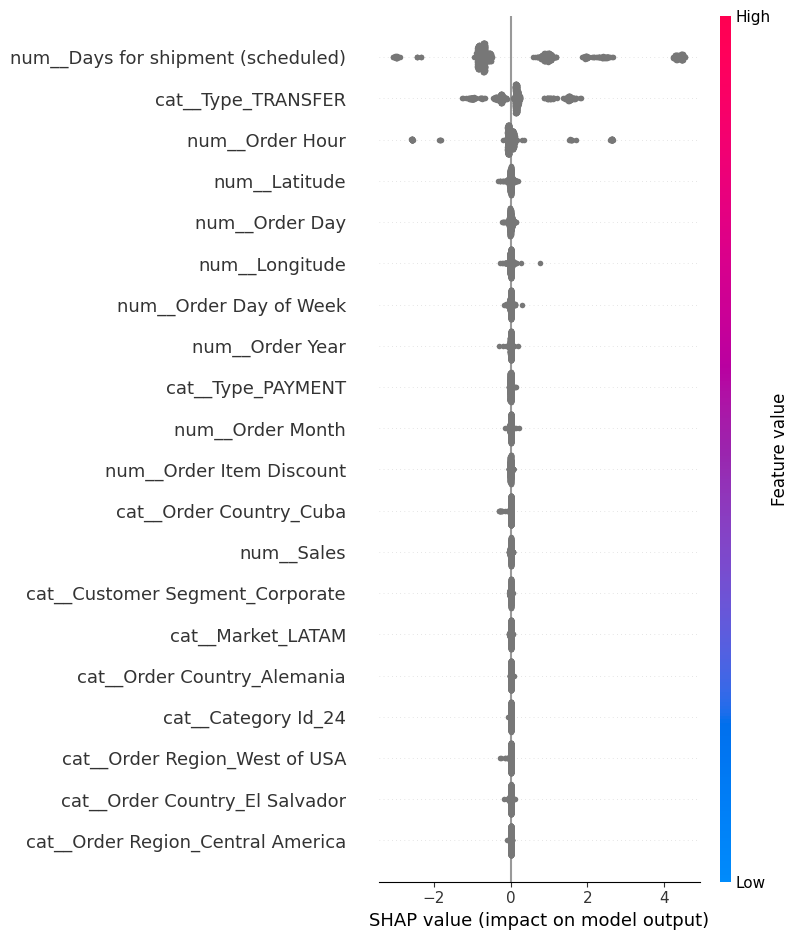

In [8]:
feature_names = preprocessor.get_feature_names_out()

shap.summary_plot(
    shap_values,
    X_sample_processed,
    feature_names=feature_names,
    max_display=20
)

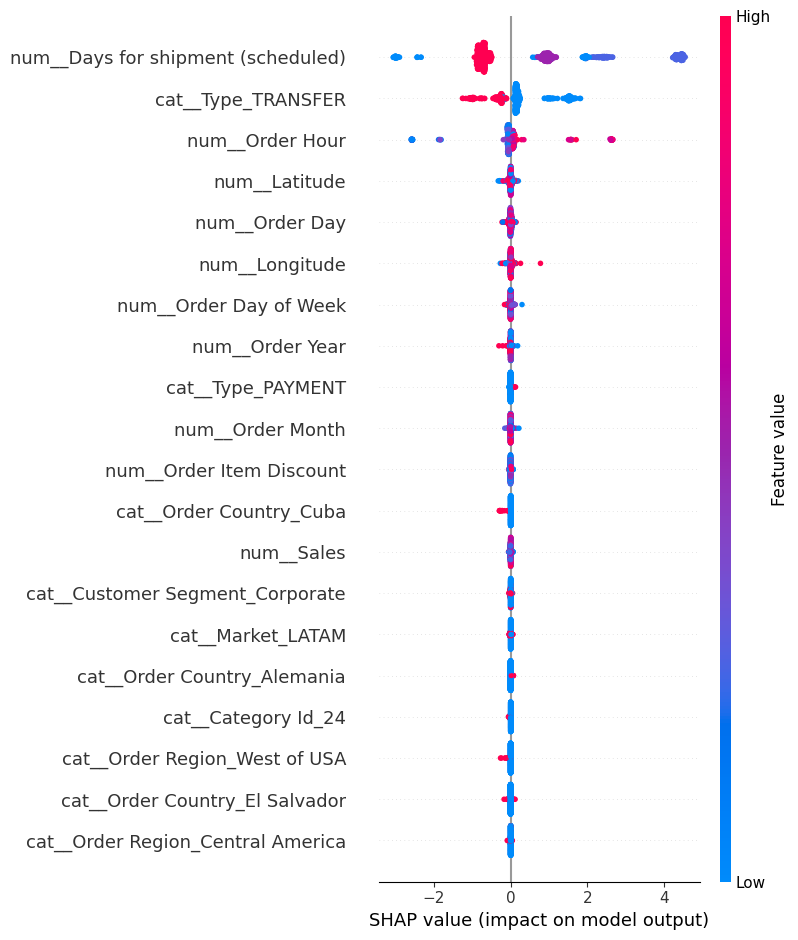

In [9]:

# SHAP summary plot with feature-value colors

import pandas as pd
import matplotlib.pyplot as plt

feature_names = preprocessor.get_feature_names_out()

X_sample_processed_df = pd.DataFrame(
    X_sample_processed.toarray()
        if hasattr(X_sample_processed, "toarray")
        else X_sample_processed,
    columns=feature_names,
    index=X_sample.index
)

shap.summary_plot(
    shap_values,
    X_sample_processed_df,
    max_display=20,
    plot_type="dot"
)


In [10]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by='Mean Absolute SHAP',
    ascending=False
).reset_index(drop=True)

print("Top 15 features by SHAP importance:")
display(shap_importance.head(15))


Top 15 features by SHAP importance:


,Feature,Mean Absolute SHAP
0,num__Days for shipment (scheduled),1.379749
1,cat__Type_TRANSFER,0.417023
2,num__Order Hour,0.202478
3,num__Latitude,0.026253
4,num__Order Day,0.023790
5,num__Longitude,0.017673
6,num__Order Day of Week,0.012380
7,num__Order Year,0.009344
8,cat__Type_PAYMENT,0.009263
9,num__Order Month,0.008859


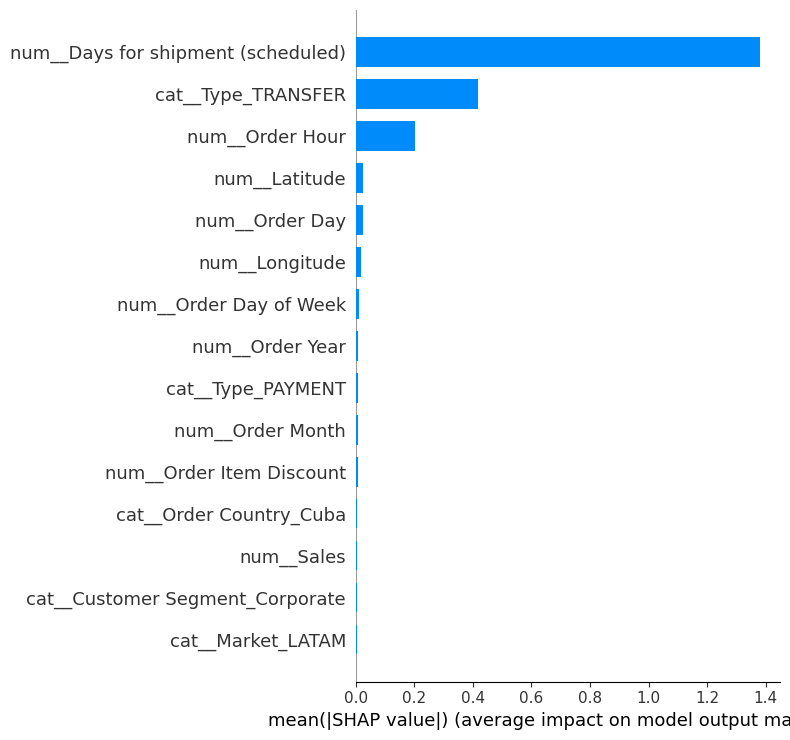

In [11]:
shap.summary_plot(
    shap_values,
    X_sample_processed_df,
    plot_type="bar",
    max_display=15
)


In [12]:

import pandas as pd

# Create one hypothetical shipment
sample_data = pd.DataFrame([{
    'Days for shipment (scheduled)': 1,
    'Order Item Discount': 50.0,
    'Order Item Quantity': 2,
    'Sales': 300.0,
    'Product Price': 150.0,
    'Latitude': 18.52,
    'Longitude': 73.85,
    'Type': 'DEBIT',
    'Customer Country': 'United States',
    'Customer Segment': 'Consumer',
    'Market': 'USCA',
    'Customer State': 'CA',
    'Order Region': 'West',
    'Order Country': 'United States',
    'Category Id': 10,
    'Product Card Id': 100,
    'Department Id': 2,
    'Order Year': 2017,
    'Order Month': 6,
    'Order Day': 15,
    'Order Day of Week': 3,
    'Order Hour': 10
}])

# Match the original input feature order using X
sample_data = sample_data[X.columns]

display(sample_data)
print("Sample shape:", sample_data.shape)


,Days for shipment (scheduled),Order Item Discount,Order Item Quantity,Sales,Product Price,Latitude,Longitude,Type,Customer Country,Customer Segment,...,Order Region,Order Country,Category Id,Product Card Id,Department Id,Order Year,Order Month,Order Day,Order Day of Week,Order Hour
0,1,50.0,2,300.0,150.0,18.52,73.85,DEBIT,United States,Consumer,...,West,United States,10,100,2,2017,6,15,3,10


Sample shape: (1, 22)


Processed sample shape: (1, 427)


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1, 5, 6, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


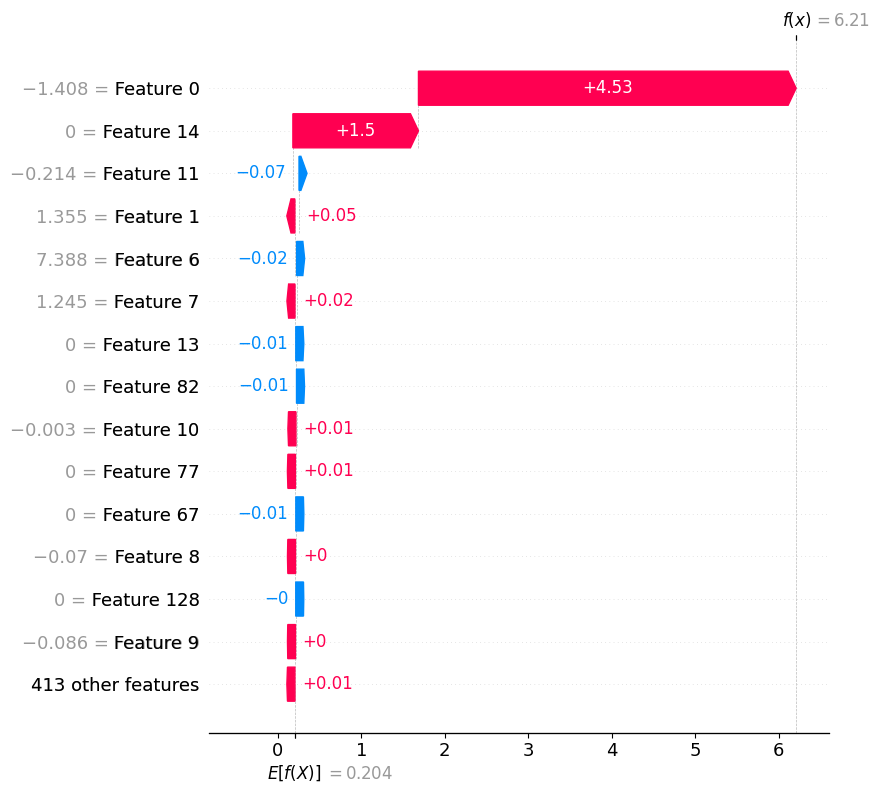

In [13]:

# Step 1: Transform the shipment using the saved preprocessor
sample_processed = preprocessor.transform(sample_data)

print("Processed sample shape:", sample_processed.shape)

# Step 2: Generate the SHAP explanation
single_explanation = explainer(sample_processed)

# Step 3: Display the waterfall plot
shap.plots.waterfall(single_explanation[0], max_display=15)


In [14]:

# Predict the probability of late delivery
late_probability = xgb_model.predict_proba(sample_processed)[0, 1]

# Apply the selected threshold from model evaluation
predicted_class = int(late_probability >= chosen_threshold)

print(f"Late-delivery probability: {late_probability:.2%}")
print(f"Classification threshold: {chosen_threshold}")

if predicted_class == 1:
    print("Prediction: HIGHER LATE-DELIVERY RISK")
else:
    print("Prediction: LOWER LATE-DELIVERY RISK")


Late-delivery probability: 99.80%
Classification threshold: 0.35
Prediction: HIGHER LATE-DELIVERY RISK


In [15]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create a table of SHAP contributions for this shipment
shap_contributions = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": np.asarray(single_explanation.values)[0]
})

# Calculate the magnitude of each contribution
shap_contributions["Absolute SHAP"] = (
    shap_contributions["SHAP Value"].abs()
)

# Display the 10 strongest contributors
top_features = (
    shap_contributions
    .sort_values("Absolute SHAP", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_features)


,Feature,SHAP Value,Absolute SHAP
0,num__Days for shipment (scheduled),4.525524,4.525524
1,cat__Type_TRANSFER,1.504618,1.504618
2,num__Order Hour,-0.073459,0.073459
3,num__Order Item Discount,0.050166,0.050166
4,num__Longitude,-0.021467,0.021467
5,num__Order Year,0.020057,0.020057
6,cat__Type_PAYMENT,-0.010312,0.010312
7,cat__Order Region_US Center,-0.008472,0.008472
8,num__Order Day of Week,0.007380,0.007380
9,cat__Order Region_South Asia,0.005804,0.005804


In [16]:

print("=" * 60)
print("INDIVIDUAL SHAP ANALYSIS — BUSINESS SUMMARY")
print("=" * 60)

print("\nPredicted late-delivery probability: 99.80%")
print("Classification threshold: 0.35")
print("Decision: Flagged as high risk")

print("\nKey findings:")
print("1. Scheduled shipment duration was the strongest contributor.")
print("2. Shipment type TRANSFER was the second strongest contributor.")
print("3. The remaining displayed features had smaller contributions.")
print("4. The shipment should be prioritized for review if this")
print("   prediction occurs in an operational setting.")

print("\nLimitations:")
print("1. This prediction concerns a hypothetical shipment.")
print("2. SHAP explains model behavior, not causation.")
print("3. A high predicted probability is not a guaranteed outcome.")
print("4. Validate explanations against real shipment outcomes.")

print("=" * 60)


INDIVIDUAL SHAP ANALYSIS — BUSINESS SUMMARY

Predicted late-delivery probability: 99.80%
Classification threshold: 0.35
Decision: Flagged as high risk

Key findings:
1. Scheduled shipment duration was the strongest contributor.
2. Shipment type TRANSFER was the second strongest contributor.
3. The remaining displayed features had smaller contributions.
4. The shipment should be prioritized for review if this
   prediction occurs in an operational setting.

Limitations:
1. This prediction concerns a hypothetical shipment.
2. SHAP explains model behavior, not causation.
3. A high predicted probability is not a guaranteed outcome.
4. Validate explanations against real shipment outcomes.


In [17]:

print("=" * 70)
print("NOTEBOOK 6 CONCLUSION — SHAP EXPLAINABILITY")
print("=" * 70)

print("""
In this notebook, SHAP (SHapley Additive exPlanations) was used
to interpret the XGBoost supply chain delivery-risk model.

Key accomplishments:
1. Generated SHAP values for a representative sample of shipments.
2. Used a summary plot to examine feature contributions across shipments.
3. Used a bar plot to rank features by mean absolute SHAP value.
4. Created an individual waterfall explanation for one shipment.
5. Examined the predicted late-delivery probability and the strongest
   individual feature contributions.
6. Documented the business interpretation and limitations.

Main findings:
- Scheduled shipment duration was the most influential feature
  in the global SHAP analysis.
- Shipment type and order hour were also influential.
- For the hypothetical shipment, scheduled duration and TRANSFER
  type were the strongest individual contributors.
- The hypothetical shipment received a predicted late-delivery
  probability of 99.80% and was flagged using the 0.35 threshold.

Business value:
SHAP explanations can help operations teams understand why the
model flags shipments, investigate risk patterns, and prioritize
shipments for review.

Limitations:
SHAP describes model behavior, not causation. The individual
prediction is hypothetical, and explanations should be validated
using real shipment outcomes before operational deployment.
""")

print("=" * 70)
print("NOTEBOOK 6 COMPLETED")
print("=" * 70)


NOTEBOOK 6 CONCLUSION — SHAP EXPLAINABILITY

In this notebook, SHAP (SHapley Additive exPlanations) was used
to interpret the XGBoost supply chain delivery-risk model.

Key accomplishments:
1. Generated SHAP values for a representative sample of shipments.
2. Used a summary plot to examine feature contributions across shipments.
3. Used a bar plot to rank features by mean absolute SHAP value.
4. Created an individual waterfall explanation for one shipment.
5. Examined the predicted late-delivery probability and the strongest
   individual feature contributions.
6. Documented the business interpretation and limitations.

Main findings:
- Scheduled shipment duration was the most influential feature
  in the global SHAP analysis.
- Shipment type and order hour were also influential.
- For the hypothetical shipment, scheduled duration and TRANSFER
  type were the strongest individual contributors.
- The hypothetical shipment received a predicted late-delivery
  probability of 99.80% and wa